In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

from numcosmo_ep2 import collapse, growth

# EdS solver comparision (4a,b)

In [28]:
ai = 1e-4
af = 1.0
delta_i = 1e-3

solA = collapse.solveCollapseA(
    ai=ai,
    af=1.0,
    delta_i=1e-3,
    omega_m0=1.0,
    omega_lambda0=0.0,
)
print("--- Solution A (a, [delta, deltaN]):")
print("Turnaround: ", collapse.findTurnaroundEvent(solA))
print("Collapse:   ", collapse.findCollapseEvent(solA))

solB = collapse.solveCollapseB(
    ai=ai,
    af=af,
    delta_i=delta_i,
    omega_m0=1.0,
    omega_lambda0=0.0,
)

print("--- Solution B (a, [delta, theta]):")
print("Turnaround: ", collapse.findTurnaroundEvent(solB))
print("Collapse:   ", collapse.findCollapseEvent(solB))

solC = collapse.solveCollapseC(
    ai=ai,
    af=af,
    delta_i=delta_i,
    omega_m0=1.0,
    omega_lambda0=0.0,
    epsilon=1e-8
)

print("--- Solution C (a, [1/delta, theta]):")
print("Turnaround: ", collapse.findTurnaroundEvent(solC))
print("Collapse:   ", collapse.findCollapseEvent(solC))

solL = collapse.solveCollapseLinear(
    ai=ai,
    af=af,
    delta_i=delta_i,
    omega_m0=1.0,
    omega_lambda0=0.0
)

--- Solution A (a, [delta, deltaN]):
Turnaround:  (np.float64(0.10636135802605702), array([ 4.55165247, 16.65495742]))
Collapse:    (np.float64(0.1688268563045276), array([1.00000000e+08, 2.99120338e+12]))
--- Solution B (a, [delta, theta]):
Turnaround:  (np.float64(0.10636135812231562), array([ 4.55165246, -3.        ]))
Collapse:    (np.float64(0.1688268562866325), array([ 1.00000000e+08, -2.99120335e+04]))
--- Solution C (a, [1/delta, theta]):
Turnaround:  (np.float64(0.10636136158981592), array([ 0.21970043, -3.        ]))
Collapse:    (np.float64(0.16882686190499646), array([ 1.00000000e-08, -2.99120342e+04]))


In [35]:
a_max = min(
    collapse.findCollapseEvent(solA)[0],
    collapse.findCollapseEvent(solB)[0],
    collapse.findCollapseEvent(solC)[0],
)

a_grid = np.logspace(np.log10(ai), np.log10(a_max), 500)
N_grid = np.log(a_grid)

# A
yA = solA.sol(N_grid)
deltaA = yA[0]
thetaA = -yA[1] / (1.0 + deltaA)
gA = 1.0 / deltaA

# B
yB = solB.sol(N_grid)
deltaB = yB[0]
thetaB = yB[1]
gB = 1.0 / deltaB

# C
yC = solC.sol(N_grid)
deltaC = 1.0 / yC[0]
thetaC = yC[1]
gC = 1.0 / deltaC

# Linear
yL = solL.sol(N_grid)
deltaL = yL[0]
deltaLN = yL[1]
gL = 1.0 / deltaL

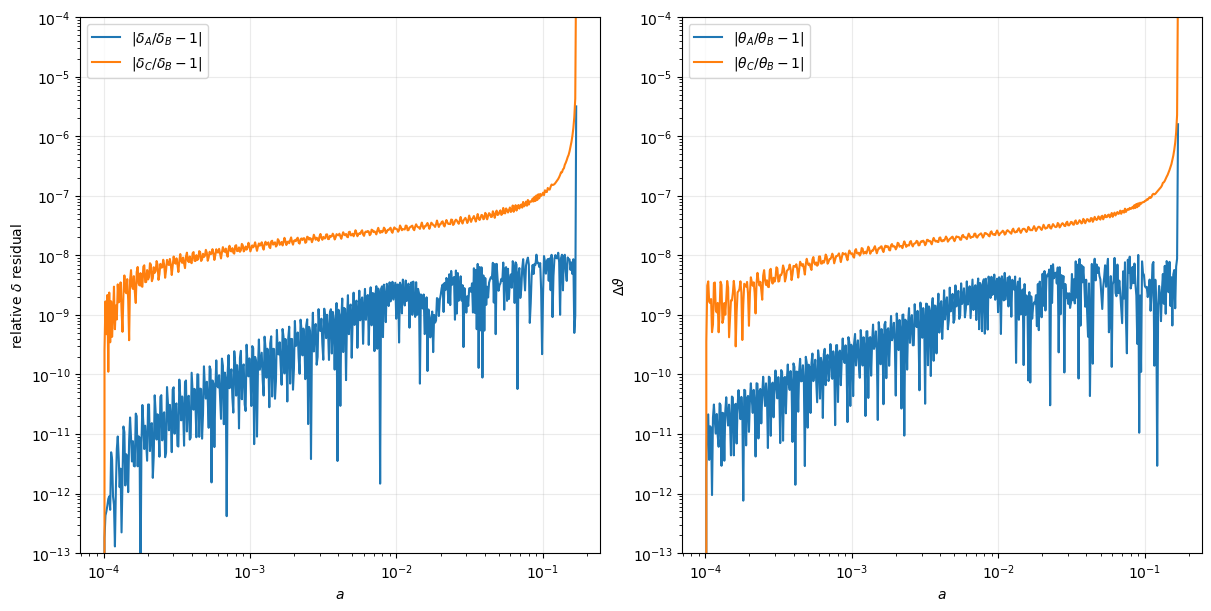

In [36]:
fig, ax = plt.subplots(ncols=2, sharex=True, figsize=(12, 6), layout="constrained")

ax[0].plot(a_grid, np.abs(deltaA/deltaB - 1.0), label=r"$|\delta_A/\delta_B-1|$")
ax[0].plot(a_grid, np.abs(deltaC/deltaB - 1.0), label=r"$|\delta_C/\delta_B-1|$")
ax[0].set_xscale("log")
ax[0].set_yscale("log")
ax[0].set_xlabel(r"$a$")
ax[0].set_ylabel(r"relative $\delta$ residual")
ax[0].set_ylim(1e-13, 1e-4)
ax[0].grid(alpha=0.25)
ax[0].legend()

ax[1].plot(a_grid, np.abs(thetaA/thetaB-1), label=r"$|\theta_A/\theta_B-1|$")
ax[1].plot(a_grid, np.abs(thetaC/thetaB-1), label=r"$|\theta_C/\theta_B-1|$")
ax[1].set_xscale("log")
ax[1].set_yscale("log")
ax[1].set_xlabel(r"$a$")
ax[1].set_ylabel(r"$\Delta\vartheta$")
ax[1].set_ylim(1e-13, 1e-4)
ax[1].grid(alpha=0.25)
ax[1].legend()

plt.savefig("../outputs/figures/04_EdS_collapse_residuals.png", dpi=200)
plt.show()

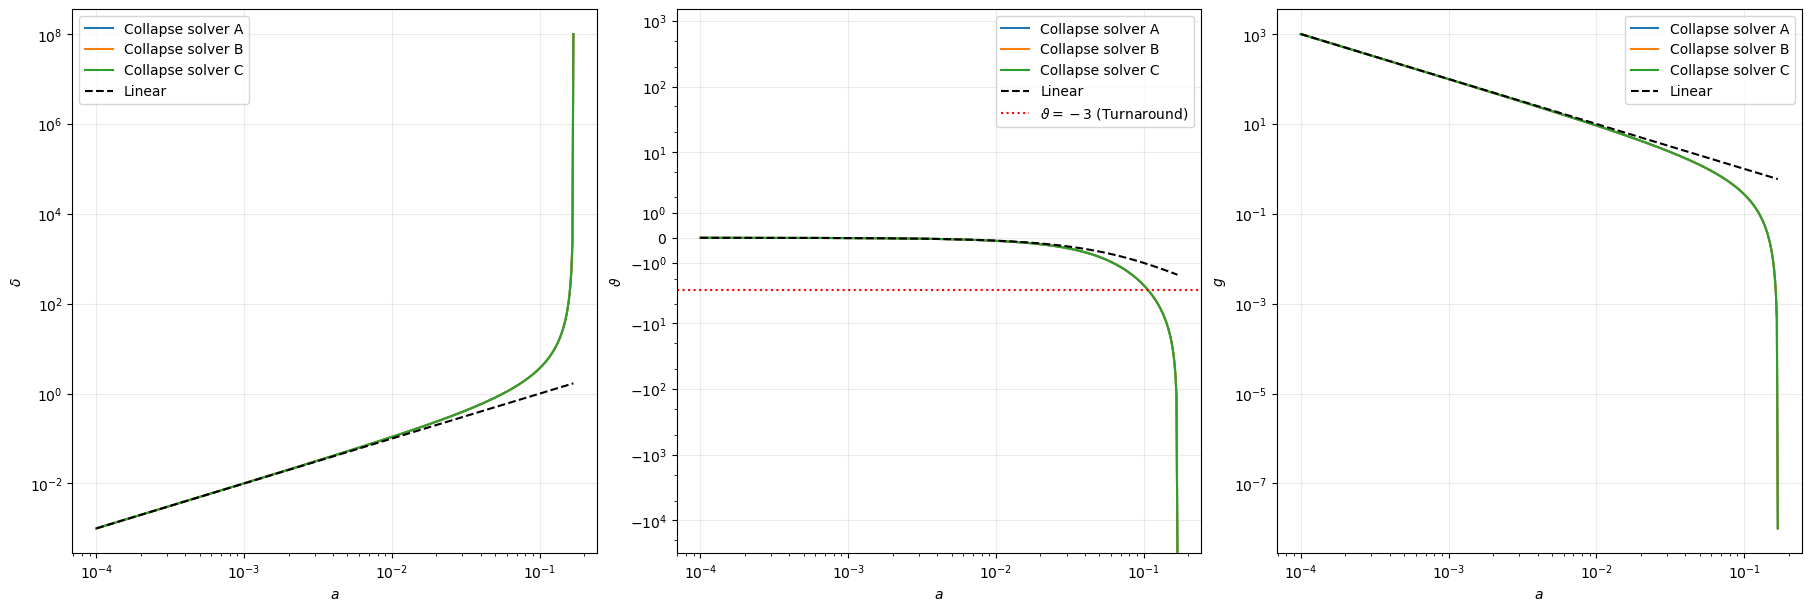

In [37]:
fig, ax = plt.subplots(ncols=3, sharex=True, figsize=(18, 6), layout="constrained")
# delta
ax[0].plot(a_grid, deltaA, "C0", label="Collapse solver A")
ax[0].plot(a_grid, deltaB, "C1", label="Collapse solver B")
ax[0].plot(a_grid, deltaC, "C2", label="Collapse solver C")
ax[0].plot(a_grid, deltaL, "k--", label="Linear")
ax[0].set_xscale("log")
ax[0].set_yscale("log")
ax[0].set_xlabel(r"$a$")
ax[0].set_ylabel(r"$\delta$")
ax[0].grid(alpha=0.25)
ax[0].legend()

# theta
ax[1].plot(a_grid, thetaA, c="C0", label="Collapse solver A")
ax[1].plot(a_grid, thetaB, c="C1", label="Collapse solver B")
ax[1].plot(a_grid, thetaC, c="C2", label="Collapse solver C")
ax[1].plot(a_grid, -deltaLN, "k--", label="Linear")
ax[1].axhline(-3.0, c="r", ls=":", label=r"$\vartheta=-3$ (Turnaround)")
ax[1].set_xscale("log")
ax[1].set_yscale("asinh")
ax[1].set_xlabel(r"$a$")
ax[1].set_ylabel(r"$\vartheta$")
ax[1].grid(alpha=0.25)
ax[1].legend()

# g
ax[2].plot(a_grid, gA, label="Collapse solver A", c="C0")
ax[2].plot(a_grid, gB, label="Collapse solver B", c="C1")
ax[2].plot(a_grid, gC, label="Collapse solver C", c="C2")
ax[2].plot(a_grid, gL, "k--", label="Linear")
ax[2].set_xscale("log")
ax[2].set_yscale("log")
ax[2].set_xlabel(r"$a$")
ax[2].set_ylabel(r"$g$")
ax[2].grid(alpha=0.25)
ax[2].legend()

plt.savefig("../outputs/figures/04_EdS_collapse_solution.png", dpi=200)
plt.show()

# EdS shooting method comparision (4c)

In [15]:
ai = 1e-5
ac = 1.0
bracket = (5e-6, 5e-5)

deltaA, solA = collapse.shootCollapseA(ai, ac, 1.0, 0.0, bracket)
deltaB, solB = collapse.shootCollapseB(ai, ac, 1.0, 0.0, bracket)
deltaC, solC = collapse.shootCollapseC(ai, ac, 1.0, 0.0, bracket)

print(deltaA, collapse.findCollapseEvent(solA)[0])
print(deltaB, collapse.findCollapseEvent(solB)[0])
print(deltaC, collapse.findCollapseEvent(solC)[0])

1.6863897514167544e-05 0.9999999991576483
1.6863897512401182e-05 0.999999999157509
1.6863898720438795e-05 0.9999999991575493


# EdS virial epoch diagnostics (4d)

In [3]:
collapse.virialDiagnostic(solA, ac=1.0, omega_m0=1.0, omega_lambda0=0.0, form="A")


a_ta = 0.630002598718718
theta_ta = -2.9999999999999996
zeta_ta = 5.551652504143282

lambda_ta = 0.0
Rvir/Rta = 0.5

Delta_vir,m = 177.61728967233515
Omega_m(ac) = 1.0
Delta_vir,c = 177.61728967233515


{'a_ta': np.float64(0.630002598718718),
 'theta_ta': np.float64(-2.9999999999999996),
 'zeta_ta': np.float64(5.551652504143282),
 'lambda_ta': np.float64(0.0),
 'y_vir': 0.5,
 'Delta_vir_m': np.float64(177.61728967233515),
 'Delta_vir_c': np.float64(177.61728967233515)}

# EdS shooting test A (4e)

In [25]:
collapse.EdS_collapse_diagnostic(1.0)

--- ac = 1.0, form = A ---
form = A
delta_i = 1.6863897582697198e-05
a_coll = 0.9999999950940357
collapse_residual = 4.905964301471499e-09
delta_c = 1.686389816109921
a_ta = 0.6300025961586315
theta_ta = -3.0000000000000004
zeta_ta = 5.5516525041432825
lambda_ta = 0.0
y_vir = 0.5
Delta_vir_m = 177.6172918376388
Delta_vir_c = 177.6172918376388

Relative errors:
a_coll: 4.905964301471499e-09
delta_c: 4.7663890670455454e-05
theta_ta: 1.4802973661668753e-16
a_ta: 6.678388490840388e-05
zeta_ta: 5.139103810545269e-09
Delta_vir_m: 0.0002003197591054558


{'a_coll': np.float64(4.905964301471499e-09),
 'delta_c': np.float64(4.7663890670455454e-05),
 'theta_ta': np.float64(1.4802973661668753e-16),
 'a_ta': np.float64(6.678388490840388e-05),
 'zeta_ta': np.float64(5.139103810545269e-09),
 'Delta_vir_m': np.float64(0.0002003197591054558)}

In [33]:
z_values = np.linspace(0, 2.0, 10)

error_listA = []
error_listB = []
error_listC = []

for zc in z_values:
    err = collapse.EdS_collapse_diagnostic(1.0 / (1.0 + zc), verbose=False, form="A")
    error_listA.append(err)

    err = collapse.EdS_collapse_diagnostic(1.0 / (1.0 + zc), verbose=False, form="B")
    error_listB.append(err)

    err = collapse.EdS_collapse_diagnostic(1.0 / (1.0 + zc), verbose=False, form="C")
    error_listC.append(err)

error_keys = [
    "a_coll",
    "delta_c",
    "theta_ta",
    "a_ta",
    "zeta_ta",
    "Delta_vir_m"
]

errorsA = {
    key: np.array([err[key] for err in error_listA])
    for key in error_keys
}
errorsB = {
    key: np.array([err[key] for err in error_listB])
    for key in error_keys
}
errorsC = {
    key: np.array([err[key] for err in error_listC])
    for key in error_keys
}

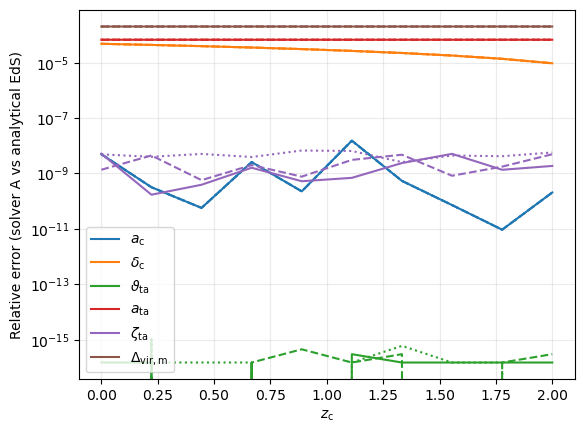

In [34]:
plt.plot(z_values, errorsA["a_coll"], label=r"$a_\mathrm{c}$", c="C0")
plt.plot(z_values, errorsB["a_coll"], c="C0", ls="--")
plt.plot(z_values, errorsC["a_coll"], c="C0", ls=":")

plt.plot(z_values, errorsA["delta_c"], label=r"$\delta_\mathrm{c}$", c="C1")
plt.plot(z_values, errorsB["delta_c"], c="C1", ls="--")
plt.plot(z_values, errorsC["delta_c"], c="C1", ls=":")

plt.plot(z_values, errorsA["theta_ta"], label=r"$\vartheta_\mathrm{ta}$", c="C2")
plt.plot(z_values, errorsB["theta_ta"], c="C2", ls="--")
plt.plot(z_values, errorsC["theta_ta"], c="C2", ls=":")

plt.plot(z_values, errorsA["a_ta"], label=r"$a_\mathrm{ta}$", c="C3")
plt.plot(z_values, errorsB["a_ta"], c="C3", ls="--")
plt.plot(z_values, errorsC["a_ta"], c="C3", ls=":")

plt.plot(z_values, errorsA["zeta_ta"], label=r"$\zeta_\mathrm{ta}$", c="C4")
plt.plot(z_values, errorsB["zeta_ta"], c="C4", ls="--")
plt.plot(z_values, errorsC["zeta_ta"], c="C4", ls=":")

plt.plot(z_values, errorsA["Delta_vir_m"], label=r"$\Delta_\mathrm{vir,m}$", c="C5")
plt.plot(z_values, errorsB["Delta_vir_m"], c="C5", ls="--")
plt.plot(z_values, errorsC["Delta_vir_m"], c="C5", ls=":")

plt.xlabel(r"$z_\mathrm{c}$")
plt.ylabel("Relative error (solver A vs analytical EdS)")
plt.yscale("log")
plt.grid(alpha=0.25)
plt.legend()
plt.savefig("../outputs/figures/04_EdS_benchmarks.png", dpi=200)
plt.show()

# Cosmology grid plot (4f)

In [16]:
omega_m_values = [0.2, 0.3, 0.4]
z_values = [0.0, 1.0, 2.0]

records = []

for form in ("A", "B", "C"):
    for omega_m0 in omega_m_values:

        omega_lambda0 = 1.0 - omega_m0

        for zc in z_values:

            ac = 1.0 / (1.0 + zc)

            diag = collapse.collapseDiagnostic(
                ac=ac,
                omega_m0=omega_m0,
                omega_lambda0=omega_lambda0,
                ai=1e-5,
                form=form,
                bracket=(5e-7, 1e-2),
                deltaInf=1e8,
                rtol=1e-8,
                atol=1e-12,
                verbose=False
            )

            records.append({
                "form": form,
                "omega_m0": omega_m0,
                "omega_lambda0": omega_lambda0,
                "zc": zc,
                "ac": ac,
                **diag
            })

In [17]:
df_cosmo = pd.DataFrame(records)

df_cosmo.to_csv(
    "../outputs/tables/collapse_cosmology_grid.csv",
    index=False
)

In [18]:
form_plot = "C"
df_plot = df_cosmo[df_cosmo["form"] == form_plot]

omega_m_values = [0.2, 0.3, 0.4]
delta_c_eds = (3.0 / 20.0 * (12.0 * np.pi)**(2.0 / 3.0))
delta_vir_eds = 18.0 * np.pi**2

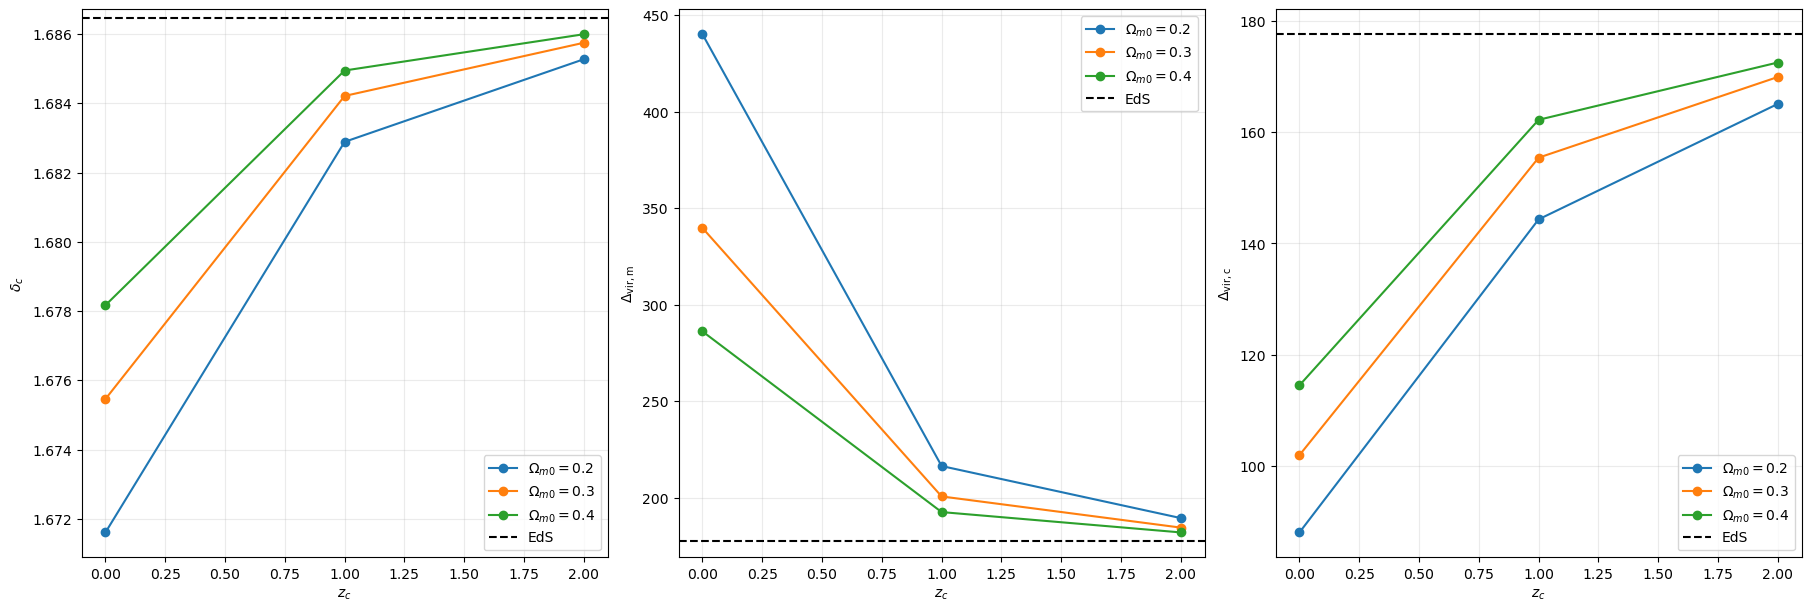

In [23]:
fig, ax = plt.subplots(ncols=3, sharex=True, figsize=(18, 6), layout="constrained")

for omega_m0 in omega_m_values:

    sub = df_plot[df_plot["omega_m0"] == omega_m0].sort_values("zc")
    label = rf"$\Omega_{{m0}}={omega_m0:.1f}$"

    # delta_c
    ax[0].plot(sub["zc"], sub["delta_c"], marker="o", label=label)
    # Delta_vir,m
    ax[1].plot(sub["zc"], sub["Delta_vir_m"], marker="o", label=label)
    # Delta_vir,c
    ax[2].plot(sub["zc"], sub["Delta_vir_c"], marker="o",label=label)


# EdS benchmarks
ax[0].axhline(delta_c_eds, linestyle="--", label="EdS", c="k")
ax[1].axhline(delta_vir_eds, linestyle="--", label="EdS", c="k")
ax[2].axhline(delta_vir_eds, linestyle="--", label="EdS", c="k")

# Labels
ax[0].set_ylabel(r"$\delta_c$")
ax[1].set_ylabel(r"$\Delta_{\rm vir,m}$")
ax[2].set_ylabel(r"$\Delta_{\rm vir,c}$")

for axi in ax:
    axi.set_xlabel(r"$z_c$")
    axi.legend()
    axi.grid(alpha=0.25)

plt.savefig("../outputs/figures/04_collapse_cosmological_grid.png", dpi=200)
plt.show()

# Numerical convergence (4g)

In [2]:
ai_values = [1e-3, 1e-4, 1e-5]
deltaInf_values = [1e5, 1e6, 1e7, 1e8]

tolerance_values = [
    (1e-5, 1e-9),
    (1e-8, 1e-12),
    (1e-10, 1e-14),
]

records = []

In [3]:
# Sweep in ai ---------------------------------------------------
for form in ("A", "B", "C"):
    for ai in ai_values:

        errors = collapse.EdS_collapse_diagnostic(
            ac=1.0,
            ai=ai,
            form=form,
            deltaInf=1e8,
            rtol=1e-8,
            atol=1e-12,
            verbose=False,
            bracket=(5e-7, 1e-2)
        )

        records.append({
            "sweep": "ai",
            "value": ai,
            "form": form,
            "ai": ai,
            "deltaInf": 1e8,
            "rtol": 1e-8,
            "atol": 1e-12,
            **errors
        })

In [4]:
# Sweep in collapse threshold -----------------------------------
for form in ("A", "B", "C"):
    for deltaInf in deltaInf_values:

        errors = collapse.EdS_collapse_diagnostic(
            ac=1.0,
            ai=1e-5,
            form=form,
            deltaInf=deltaInf,
            rtol=1e-8,
            atol=1e-12,
            verbose=False,
            bracket=(5e-7, 1e-2)
        )

        records.append({
            "sweep": "threshold",
            "value": deltaInf,
            "form": form,
            "ai": 1e-5,
            "deltaInf": deltaInf,
            "rtol": 1e-8,
            "atol": 1e-12,
            **errors
        })

In [5]:
# Sweep in solver tolerances ------------------------------------
for form in ("A", "B", "C"):
    for rtol, atol in tolerance_values:

        errors = collapse.EdS_collapse_diagnostic(
            ac=1.0,
            ai=1e-5,
            form=form,
            deltaInf=1e8,
            rtol=rtol,
            atol=atol,
            verbose=False,
            bracket=(5e-7, 1e-2)
        )

        records.append({
            "sweep": "tolerance",
            "value": rtol,
            "form": form,
            "ai": 1e-5,
            "deltaInf": 1e8,
            "rtol": rtol,
            "atol": atol,
            **errors
        })

In [6]:
df = pd.DataFrame(records)

output_dir = Path("../outputs/tables")
output_dir.mkdir(parents=True, exist_ok=True)

df.to_csv(
    output_dir / "collapse_convergence.csv",
    index=False
)

In [7]:
print(df.to_string(index=False))

    sweep        value form      ai    deltaInf         rtol         atol       a_coll  delta_c     theta_ta     a_ta      zeta_ta  Delta_vir_m
       ai 1.000000e-03    A 0.00100 100000000.0 1.000000e-08 1.000000e-12 1.332268e-15 0.001848 2.960595e-16 0.000067 3.870744e-09     0.000200
       ai 1.000000e-04    A 0.00010 100000000.0 1.000000e-08 1.000000e-12 3.005913e-09 0.000124 1.480297e-16 0.000067 4.624464e-09     0.000200
       ai 1.000000e-05    A 0.00001 100000000.0 1.000000e-08 1.000000e-12 2.627565e-12 0.000048 0.000000e+00 0.000067 5.139104e-09     0.000200
       ai 1.000000e-03    B 0.00100 100000000.0 1.000000e-08 1.000000e-12 1.887379e-15 0.001848 0.000000e+00 0.000067 3.190510e-09     0.000200
       ai 1.000000e-04    B 0.00010 100000000.0 1.000000e-08 1.000000e-12 2.999001e-09 0.000124 0.000000e+00 0.000067 9.656566e-10     0.000200
       ai 1.000000e-05    B 0.00001 100000000.0 1.000000e-08 1.000000e-12 2.622569e-12 0.000048 1.480297e-16 0.000067 1.349285e-09     0